# Census income classification (UCI Adult)

**Author:** Mohamed Hassan Elsisi. A personal portfolio project, reviewed for data leakage and reproducibility.

**Goal.** Predict whether a person in the UCI Adult census data earns more than $50K a year, with a leak-free pipeline, a fair comparison of models, and an honest look at the limits of using demographic data.

**Outline.** 1 Data and EDA · 2 Split · 3 Preprocessing · 4 Model comparison · 5 Tuning · 6 Feature selection · 7 Final model and test evaluation · 8 Error analysis · 9 Fairness inspection · 10 Robustness checks · 11 Reflection and consistency check.

**Data source.** Becker, B. and Kohavi, R. (1996). *Adult*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/2/adult

**How to run.** Install the package (`pip install -e .`), put `adult.data` and `adult.test` in `data/raw/` (see `data/README.md`) and run all cells. Reusable code lives in `src/census_income/`; this notebook is the narrative layer. Expected runtime: about 13 minutes on one CPU core.

## 0. Setup

In [20]:
import time, warnings
import numpy as np
import pandas as pd
import sklearn, matplotlib
from IPython.display import Image, display
from sklearn.base import clone
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold

from census_income import analysis, plots
from census_income.config import (DEFAULT_DATA_DIR, DEFAULT_FIGURES_DIR, DEFAULT_RESULTS_DIR, N_FOLDS,
                                  RANDOM_STATE, THRESHOLD_GRID, USED_COLS, CAT_COLS)
from census_income.data import (data_quality_report, exact_overlap_mask, load_adult, load_adult_files, make_split)
from census_income.evaluation import (bootstrap_metric_ci, cross_validate_oof, evaluate_at_threshold,
                                       select_threshold, summarise_folds)
from census_income.fairness import gap_ci, group_report, group_report_ci
from census_income.modeling import baseline, default_models, gb_pipeline
from census_income.preprocessing import final_preprocessor

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG_DIR = DEFAULT_FIGURES_DIR
T0 = time.time()
import sys
print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

python 3.14.7 | scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2


## 1. Data and exploratory analysis

The UCI repository ships `adult.data` and `adult.test`. I stack them into one table (48,842 records) and create my own stratified split in section 2. Two details of the files: missing values are written as `?`, which is read as `NaN`, and the labels in `adult.test` end with a full stop (`>50K.`), which is stripped so both files use the same labels. The loader also skips the comment line at the top of `adult.test`.

official train: (32561, 15) | official test: (16281, 15) | combined: (48842, 16)


,value
n_records,48842.000000
n_feature_columns,14.000000
pos_share,0.239282
workclass_and_occupation_both_missing,2799.000000
exact_duplicate_rows,52.000000
feature_duplicate_rows_ignoring_label,57.000000
feature_groups_with_conflicting_labels,5.000000
whitespace_issues_in_text_columns,0.000000


,missing
workclass,2799
occupation,2809
native-country,857


,age,capital-gain,capital-loss,hours-per-week
count,48842.0,48842.0,48842.0,48842.0
mean,38.6,1079.1,87.5,40.4
std,13.7,7452.0,403.0,12.4
min,17.0,0.0,0.0,1.0
25%,28.0,0.0,0.0,40.0
50%,37.0,0.0,0.0,40.0
75%,48.0,0.0,0.0,45.0
max,90.0,99999.0,4356.0,99.0


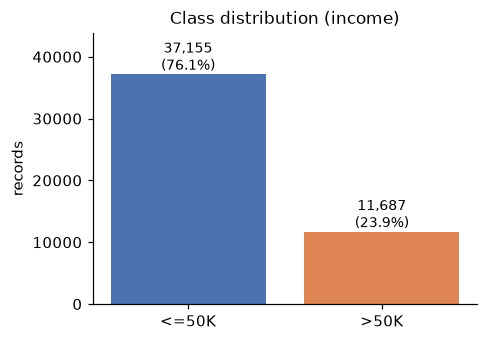

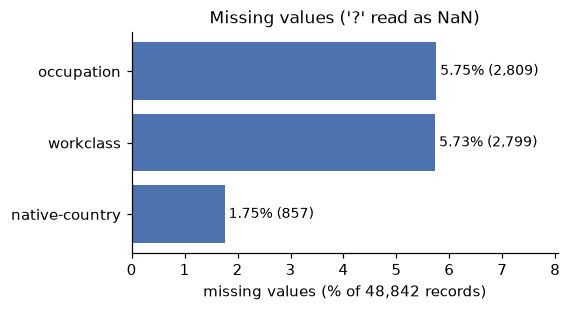

In [21]:
train_official, test_official = load_adult_files(DEFAULT_DATA_DIR)
df = load_adult(DEFAULT_DATA_DIR)
quality = data_quality_report(df)
print("official train:", train_official.shape, "| official test:", test_official.shape, "| combined:", df.shape)
display(pd.Series({k: v for k, v in quality.items() if not isinstance(v, dict)}, name="value").to_frame())
display(pd.DataFrame({"missing": quality["missing"]}))
display(df[["age", "capital-gain", "capital-loss", "hours-per-week"]].describe().round(1))
display(Image(plots.class_distribution(df, FIG_DIR)))
display(Image(plots.missing_values(df, FIG_DIR)))

**Class distribution.** About 76% of people earn at most $50K and 24% earn more, so the classes are imbalanced (37,155 against 11,687).

**Missing values and basic checks.** `workclass` (2,799 rows, 5.73%), `occupation` (2,809, 5.75%) and `native-country` (857, 1.75%) have missing values, and every row with a missing `workclass` also lacks `occupation`. The numeric columns have none, but the pipeline still imputes them so it would also work on new data with gaps.

There are 52 exact duplicate rows (57 rows if the label is ignored) and 5 groups of rows with identical features but different labels. I kept all of them so the data matches the 48,842 records of the original brief; the effect on the metrics is negligible (see the overlap check in sections 2 and 10). `capital-gain` is very skewed: the median is 0 and the maximum is 99,999, a top-coded value.

## 2. Train/test split

I split 80/20 with `stratify=y` and `random_state=42`. The test set is not used again until section 7. From here on, every exploration that involves the target uses the training data only. The counts and the `describe()` table above are computed on all 48,842 rows before the split. They are descriptive only: no modelling decision uses them.

train: (39073, 14) | test: (9769, 14) | positive share train/test: 0.2393 / 0.2393
test rows identical to a training row: 18 (0.18% of test)


,training data only
positive_rate,0.239
positive_rate_workclass_missing,0.094
n_workclass_missing,2233.000
share_capital_gain_zero,0.918
positive_rate_capital_gain_positive,0.618
capital_gain_top_coded_count,181.000
positive_rate_married_civ_spouse,0.445
positive_rate_never_married,0.046


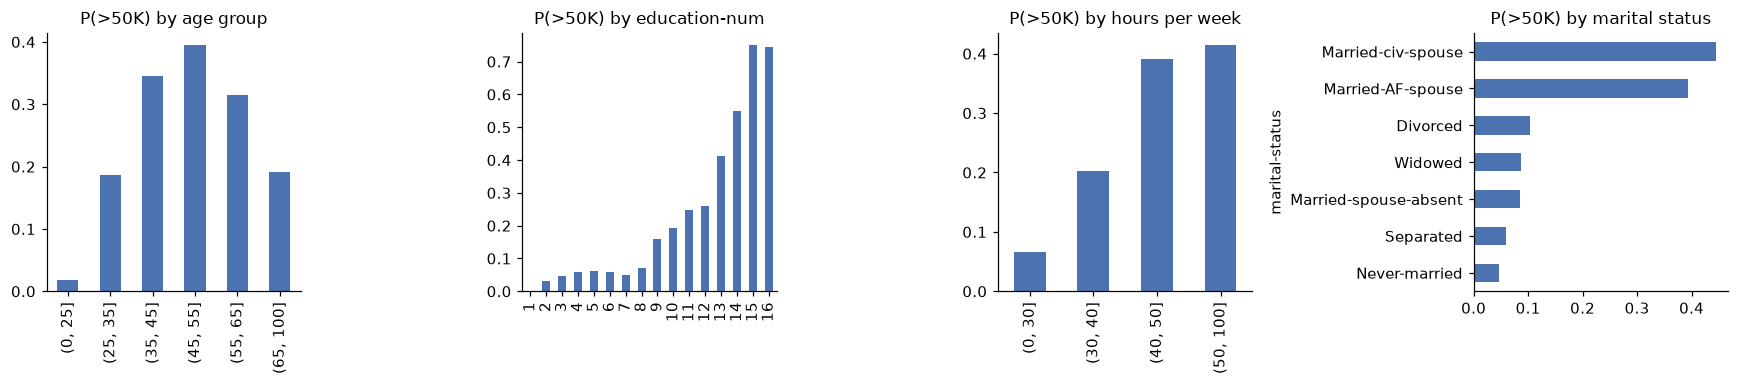

In [22]:
X_train, X_test, y_train, y_test = make_split(df)
overlap = exact_overlap_mask(X_train, X_test)
print("train:", X_train.shape, "| test:", X_test.shape,
      "| positive share train/test: %.4f / %.4f" % (y_train.mean(), y_test.mean()))
print("test rows identical to a training row:", int(overlap.sum()), "(%.2f%% of test)" % (100 * overlap.mean()))
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
display(pd.Series(analysis.eda_train_summary(X_train, y_train), name="training data only").round(3).to_frame())
display(Image(plots.eda_target_relations(X_train, y_train, FIG_DIR)))

**Duplicates across the split.** 18 test rows (0.18% of the test set) are exact copies of a training row. I kept them; section 10 shows that the test F1 is unchanged when they are excluded.

**Observations (training data only).**

1. **Age, education and hours matter.** The share earning >50K peaks for people aged 45 to 55, is low up to `education-num` 8 and rises steeply above 12, and grows with weekly hours (see the figure).
2. **Marital status is very strong.** 44.5% of married-civ-spouse people earn >50K against 4.6% of never-married people.
3. **Missingness carries information.** The 2,233 training rows with a missing `workclass` also lack `occupation`, and only 9.4% of them earn >50K (24% overall). I therefore keep them and encode the gap as an "Unknown" category instead of dropping rows or using the mode.
4. **Capital gain is mostly zero but decisive.** 91.8% of people have no capital gain, and among those who do, 61.8% earn >50K. 181 training rows sit at the top-coded value 99,999.

## 3. Preprocessing

All steps live in one `ColumnTransformer` inside a `Pipeline` (`census_income.preprocessing`), so every statistic is fitted on the training part of each fold only.

- **Numeric** (`age`, `education-num`, `hours-per-week`, `capital-gain`, `capital-loss`): median imputation, then standard scaling. Scaling is switched off for the tree models because it does not change their splits.
- **Categorical** (`workclass`, `marital-status`, `occupation`, `relationship`): impute with the constant "Unknown", then one-hot encode with `handle_unknown="ignore"`.
- **Dropped:** `fnlwgt` (a survey sampling weight, not a property of the person), `education` (the same information as `education-num`), and `race` and `sex` (excluded as model inputs; they are only inspected in section 9).

Two preprocessing choices were decided with 5-fold CV on the training set, using plain logistic regression as the probe.

In [23]:
probes = analysis.preprocessing_probes(X_train, y_train, cv)
display(probes.round(4))
assert not {"race", "sex"} & set(USED_COLS)
print("features used:", USED_COLS)
print("encoded columns:", len(final_preprocessor(True).fit(X_train).get_feature_names_out()))

,f1,f1_std,roc_auc,n_features
variant,,,,
raw capital + native-country,0.6571,0.0057,0.9052,84
log1p capital + native-country,0.6453,0.0059,0.8990,84
"raw capital, no native-country",0.6560,0.0061,0.9051,42


features used: ['age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'workclass', 'marital-status', 'occupation', 'relationship']
encoded columns: 42


`log1p` on the capital columns made logistic regression slightly worse (F1 0.645 against 0.657, ROC AUC 0.899 against 0.905), so they stay raw. Dropping `native-country` costs almost nothing (F1 0.656 against 0.657, far below the fold standard deviation of about 0.006) and halves the number of encoded columns from 84 to 42. It is also a proxy for national origin, so I drop it.

## 4. Model comparison

Three models are compared with the same stratified 5-fold CV on the training data: logistic regression (scaled inputs), random forest and gradient boosting, plus a majority-class baseline. Precision, recall and F1 are computed for the positive class (>50K), and ROC AUC is added. The table shows the mean and the population standard deviation (ddof=0) over the 5 folds.

**Why accuracy alone is not enough.** The baseline that always answers "<=50K" reaches 0.761 accuracy and finds none of the high earners (recall 0, F1 0). The best model reaches about 0.866, so accuracy shrinks a large real difference into ten points. The positive class is the one that matters here, so precision, recall and F1 on >50K describe the models much better.

,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,fit_time_s
model,,,,,,,,,,,
Majority-class baseline,0.7607,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0027
Logistic Regression,0.8510,0.0020,0.7331,0.0049,0.5935,0.0089,0.6560,0.0061,0.9051,0.0009,0.1069
Random Forest,0.8469,0.0027,0.7061,0.0096,0.6172,0.0051,0.6586,0.0040,0.8925,0.0018,19.5633
Gradient Boosting,0.8664,0.0030,0.7867,0.0109,0.6061,0.0108,0.6846,0.0076,0.9204,0.0016,1.5042


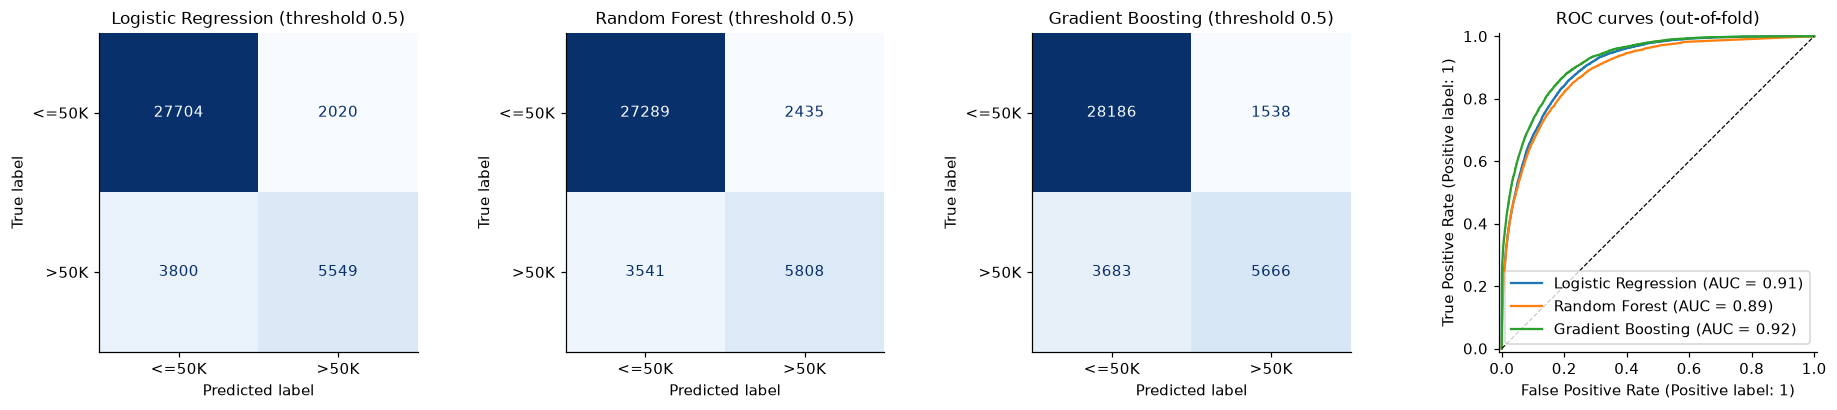

In [24]:
models = default_models()
cv_rows, oof = [], {}
folds, _ = cross_validate_oof(baseline(), X_train, y_train, cv)
cv_rows.append(summarise_folds("Majority-class baseline", folds))
for name, pipe in models.items():
    folds, oof[name] = cross_validate_oof(pipe, X_train, y_train, cv)
    cv_rows.append(summarise_folds(name, folds))
cv_default = pd.DataFrame(cv_rows).set_index("model")
display(cv_default.round(4))
display(Image(plots.cv_confusion_roc(y_train, oof, FIG_DIR)))

Gradient boosting is best on accuracy, precision, F1 and ROC AUC (F1 0.685 ± 0.008, AUC 0.920). Random forest has slightly higher recall (0.617) but the lowest precision (0.706). Logistic regression is the weakest on F1 (0.656) but by far the fastest to fit. The confusion matrices come from out-of-fold predictions at threshold 0.5. All three models miss around 40% of the high earners at this threshold, which section 7 addresses.

## 5. Tuning

Each model gets its own small grid, scored on F1 with the same folds, so the comparison is not tilted towards one model. The grids are small on purpose, to keep the runtime reasonable. The best score is the maximum over a few settings, so it is slightly optimistic, but this applies equally to all three models. All tuning uses the training set only.

In [25]:
searches, tuned_df, edge = analysis.tune_all(models, X_train, y_train, cv, log=lambda m: None)
display(tuned_df.round(4))
display(pd.DataFrame(edge))
best_gb = {k.replace("clf__", ""): v for k, v in searches["Gradient Boosting"].best_params_.items()}
nb_df = analysis.gb_neighbour_settings(X_train, y_train, cv, searches["Gradient Boosting"].best_score_)
display(nb_df.round(4))

,best_params,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std
model,,,,,,,,,,,
Logistic Regression,{'C': 10},0.8511,0.0021,0.7329,0.0050,0.5943,0.0085,0.6563,0.0061,0.9051,0.0010
Random Forest,"{'max_depth': 20, 'min_samples_leaf': 2}",0.8635,0.0026,0.7779,0.0070,0.6012,0.0125,0.6781,0.0081,0.9185,0.0017
Gradient Boosting,"{'max_depth': 5, 'n_estimators': 150}",0.8728,0.0023,0.7793,0.0081,0.6532,0.0063,0.7107,0.0048,0.9279,0.0008


,model,param,best,grid,on_edge
0,Logistic Regression,C,10,"[0.01, 0.1, 1, 10]",True
1,Random Forest,max_depth,20,"[12, 20]",True
2,Random Forest,min_samples_leaf,2,"[2, 5]",True
3,Gradient Boosting,n_estimators,150,"[150, 250]",True
4,Gradient Boosting,max_depth,5,"[3, 4, 5]",True


,f1
setting,
"depth 5, 150 trees (grid best)",0.7107
"depth 6, 150 trees",0.7108
"depth 5, 100 trees",0.7068


In the tuned table, gradient boosting is clearly ahead on F1 (0.711), followed by random forest (0.678) and logistic regression (0.656). The best value of every parameter sits on the edge of its grid, which can mean a better setting lies outside. The two settings just outside the grid for gradient boosting score 0.7109 and 0.7068, against 0.7107 for the grid winner. The curve is flat: differences of 0.0002 are far below the fold standard deviation (about 0.005), so a larger search is unlikely to change the picture. For logistic regression, C=10 beats C=1 by only 0.0003, which is also a plateau.

## 6. Feature selection / regularisation

I use **L1-regularised logistic regression**, with the same pipeline and an **L2 logistic regression (C=1)** as baseline. L1 pushes weak coefficients to exactly zero, so it doubles as feature selection. I compare several values of C by cross-validated F1.

,penalty,C,f1,f1_std,roc_auc,non-zero coefficients,original features kept
0,L2 (baseline),1.00,0.6559,0.0063,0.9051,42,9
1,L1,1.00,0.6562,0.0062,0.9051,35,9
2,L1,0.10,0.6536,0.0066,0.9048,30,9
3,L1,0.03,0.6485,0.0056,0.9035,27,9
4,L1,0.01,0.6343,0.0069,0.8990,15,9


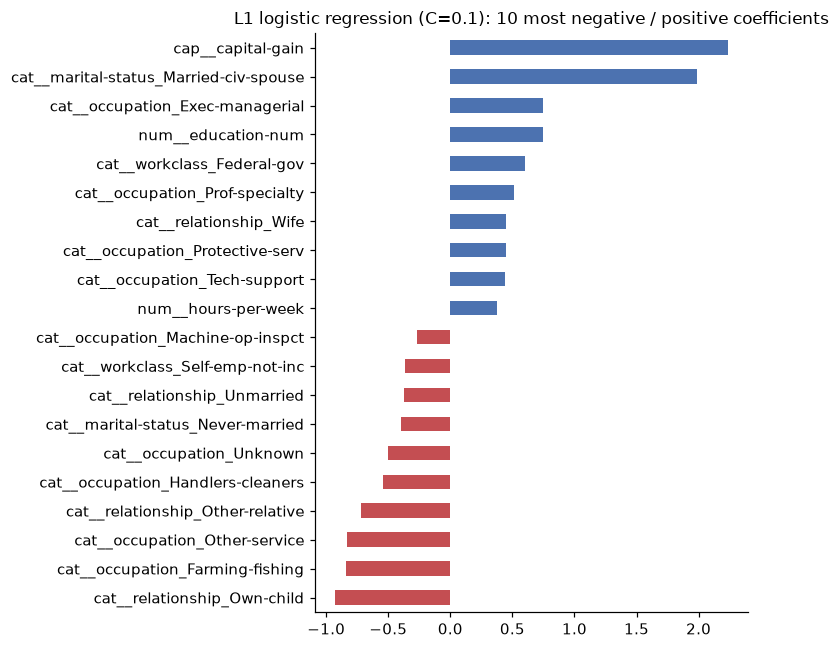

,coefficient
cat__occupation_Prof-specialty,0.51
cat__workclass_Federal-gov,0.60
num__education-num,0.75
cat__occupation_Exec-managerial,0.75
cat__marital-status_Married-civ-spouse,1.99
cap__capital-gain,2.24


In [26]:
fs_df, l1_coef = analysis.l1_vs_l2(X_train, y_train, cv)
display(fs_df.round(4))
display(Image(plots.l1_coefficients(l1_coef, FIG_DIR)))
display(l1_coef[l1_coef != 0].sort_values().tail(6).round(2).to_frame("coefficient"))

L2 scores F1 0.6558. L1 with C=1 matches it (0.6562) with 35 non-zero coefficients, and C=0.1 keeps 30 for a loss of 0.002, well inside the fold standard deviation (about 0.007). Going further hurts: 27 coefficients at C=0.03 cost 0.007, and 15 at C=0.01 cost 0.022. C=0.1 is the knee of the curve. Every original column still has at least one non-zero dummy, so L1 removes individual categories rather than whole columns.

The strongest positive coefficients are `capital-gain` (2.24) and `marital-status = Married-civ-spouse` (1.99), followed by `education-num` and `Exec-managerial` (both 0.75). Numeric inputs are standardised and one-hot columns are not, so sizes are only compared loosely.

Next, the same L1 model (`SelectFromModel`) is put in front of gradient boosting.

In [27]:
fs_gb = analysis.gb_selection_comparison(X_train, y_train, best_gb, cv)
display(fs_gb.round(4))

,f1,f1_std,roc_auc,avg features
setup,,,,
"GB, all features",0.7107,0.0048,0.9279,42.0
"GB, L1-selected features",0.7102,0.0048,0.9274,30.8


Gradient boosting with L1-selected inputs scores F1 0.7102 and AUC 0.9274, against 0.7107 and 0.9279 with all 42 columns, using about 31 inputs instead of 42. The selection step therefore does not improve accuracy; its only benefit is a somewhat smaller input set. I keep it because it costs nothing measurable and was part of the original design, but I would not claim it improves the model. Gradient boosting does not need an external selector.

In [28]:
stab = analysis.selection_stability(X_train, y_train, n_boot=30)
print("resamples: 5 CV training parts + 30 bootstrap samples (training data only)")
print("always selected:", int((stab.selection_frequency == 1).sum()), "| never selected:", int((stab.selection_frequency == 0).sum()),
      "| sometimes:", int(((stab.selection_frequency > 0) & (stab.selection_frequency < 1)).sum()))
display(stab[(stab.selection_frequency > 0) & (stab.selection_frequency < 1)].round(3).reset_index(drop=True))

resamples: 5 CV training parts + 30 bootstrap samples (training data only)
always selected: 23 | never selected: 3 | sometimes: 16


,feature,selection_frequency
0,cat__occupation_Tech-support,0.971
1,cat__workclass_Self-emp-inc,0.971
2,cat__workclass_Local-gov,0.943
3,cat__occupation_Adm-clerical,0.800
4,cat__marital-status_Divorced,0.714
5,cat__marital-status_Widowed,0.686
6,cat__occupation_Priv-house-serv,0.600
7,cat__marital-status_Separated,0.600
8,cat__occupation_Craft-repair,0.486
9,cat__occupation_Transport-moving,0.486


Across 35 resamples (the 5 CV training parts and 30 bootstrap samples), 23 of the 42 encoded columns are always selected, 3 are never selected and 16 are selected only sometimes. The unstable ones are mostly small categories or dummies that overlap with others (for example `relationship = Husband` overlaps with `marital-status = Married-civ-spouse`), which is the usual behaviour of L1 on correlated inputs. The important columns (capital gain, education, age, hours, married-civ-spouse) are stable, so the selection is reasonable, but the exact list of 30 to 33 columns should not be over-interpreted.

## 7. Final model and test evaluation

Final model: gradient boosting (best tuned CV F1) behind the L1 selection step, with `max_depth=5`, `n_estimators=150` and the default learning rate 0.1.

At the default threshold of 0.5 every model has recall around 0.6, and the metric of interest is F1 on the >50K class. The decision threshold is therefore chosen on **out-of-fold probabilities of the training set** (the test set plays no role).

OOF F1 at 0.50: 0.7102 | best threshold 0.35: OOF F1 0.7272


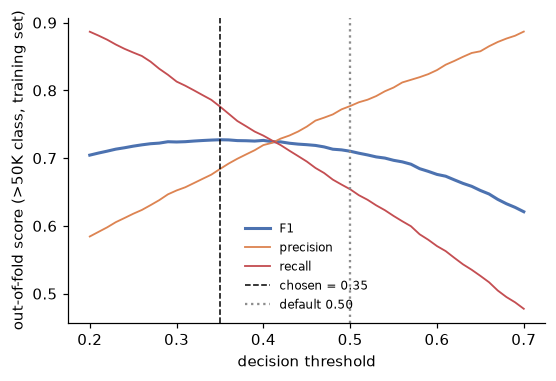

In [29]:
final_model = gb_pipeline(best_gb, with_selection=True)
oof_final = cross_validate_oof(final_model, X_train, y_train, cv)[1]
THRESHOLD, f1_scores = select_threshold(y_train, oof_final)
print("OOF F1 at 0.50: %.4f | best threshold %.2f: OOF F1 %.4f" % (f1_scores[list(THRESHOLD_GRID).index(0.5)], THRESHOLD, f1_scores.max()))
display(Image(plots.threshold_curves(y_train, oof_final, THRESHOLD_GRID, f1_scores, THRESHOLD, FIG_DIR)))

The best threshold is 0.35: out-of-fold F1 rises from 0.7102 at 0.5 to 0.7272. Because the threshold was picked on the same out-of-fold predictions that are used to report that number, 0.7272 is very slightly optimistic. The model and threshold are now fixed, and the test set is used **once**.

L1 selector threshold: 1e-05 | features kept: 33 of 42


,test value,95% CI low,95% CI high
precision,0.6924,0.6741,0.7094
recall,0.7665,0.7491,0.7835
f1,0.7276,0.7135,0.7410
accuracy,0.8626,0.8562,0.8688
roc_auc,0.9298,0.9247,0.9349
avg_precision,0.8310,0.8174,0.8443


{'tn': 6635, 'fp': 796, 'fn': 546, 'tp': 1792}
              precision    recall  f1-score   support

       <=50K      0.924     0.893     0.908      7431
        >50K      0.692     0.766     0.728      2338

    accuracy                          0.863      9769
   macro avg      0.808     0.830     0.818      9769
weighted avg      0.869     0.863     0.865      9769



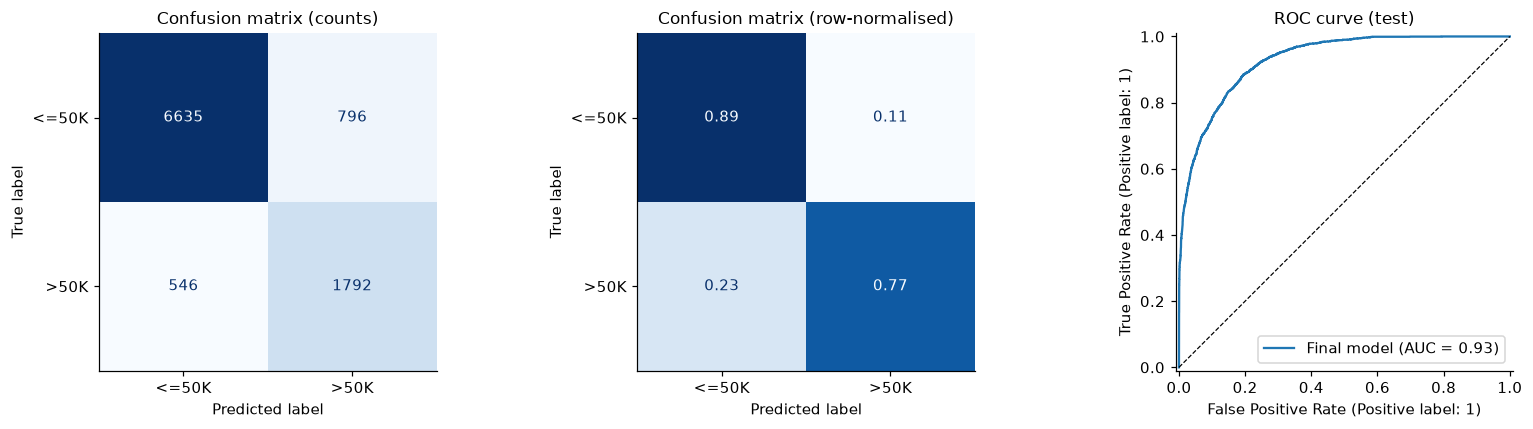

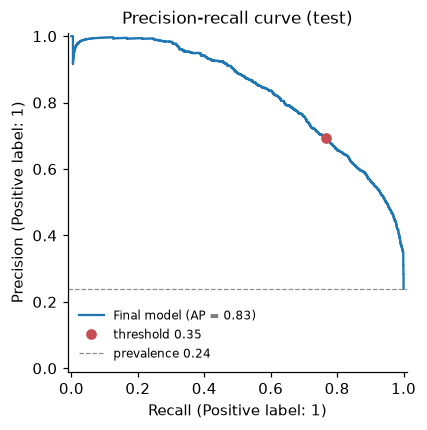

In [30]:
final_model = clone(final_model).fit(X_train, y_train)
sel = final_model.named_steps["select"]
print("L1 selector threshold:", sel.threshold_, "| features kept:", int(sel.get_support().sum()), "of", len(sel.get_support()))

y_proba = final_model.predict_proba(X_test)[:, 1]          # the single use of the test set
y_pred = (y_proba >= THRESHOLD).astype(int)
test = evaluate_at_threshold(y_test, y_proba, THRESHOLD)
ci = bootstrap_metric_ci(y_test, y_proba, THRESHOLD, n_boot=1000)
display(pd.DataFrame({k: {"test value": v["estimate"], "95% CI low": v["lo"], "95% CI high": v["hi"]} for k, v in ci.items()}).T.round(4))
print({k: test[k] for k in ("tn", "fp", "fn", "tp")})
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"], digits=3))
display(Image(plots.final_test(y_test, y_pred, y_proba, FIG_DIR)))
display(Image(plots.precision_recall(y_test, y_proba, THRESHOLD, FIG_DIR)))

**Test results.** Precision 0.692, recall 0.766, F1 0.728, ROC AUC 0.930, average precision 0.831 and accuracy 0.863 on the >50K class. The confusion matrix has 6,635 true negatives, 796 false positives, 546 false negatives and 1,792 true positives. The 95% bootstrap intervals above (F1 0.714 to 0.741) describe test-sample noise only; they do not include variation from re-training. The out-of-fold F1 on the training data was 0.727, so cross-validation and test agree and there is no sign of overfitting to the folds.

**Accuracy is not the headline number.** Accuracy is 0.863 but the majority-class baseline already gets 0.761 on this split, so F1, precision, recall and the PR curve are the metrics that describe the >50K class.

## 8. Error analysis

,FP,FN,TP,all test
age,45.000,42.500,45.00,38.600
education-num,11.300,10.000,12.00,10.100
hours-per-week,46.000,42.400,45.70,40.200
share capital-gain > 0,0.019,0.004,0.29,0.086
share married-civ-spouse,0.926,0.683,0.91,0.453


top occupations: {'FP': {'Exec-managerial': 0.197, 'Prof-specialty': 0.191, 'Craft-repair': 0.161, 'Sales': 0.156}, 'FN': {'Craft-repair': 0.203, 'Prof-specialty': 0.122, 'Sales': 0.115, 'Machine-op-inspct': 0.105}}
mean predicted probability: {'FP': 0.542, 'FN': 0.193}


,permutation importance (drop in ROC AUC)
marital-status,0.0669
capital-gain,0.0508
education-num,0.0332
age,0.0328
capital-loss,0.0181
occupation,0.0178
relationship,0.0142
hours-per-week,0.0135
workclass,0.0034


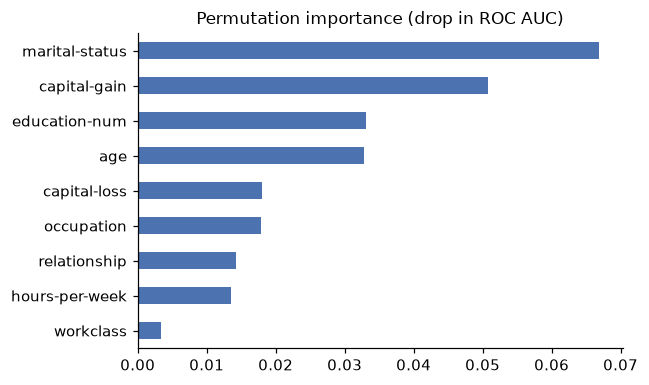

In [31]:
ep = analysis.error_profile(X_test, y_test, y_pred, y_proba)
display(ep["profile"])
print("top occupations:", ep["occupation_top"])
print("mean predicted probability:", {k: round(v, 3) for k, v in ep["mean_proba"].items()})
pi_s = analysis.permutation_importance_train(final_model, X_train, y_train)
display(pi_s.round(4).to_frame("permutation importance (drop in ROC AUC)"))
display(Image(plots.permutation_importance_plot(pi_s, FIG_DIR)))

**False positives (796).** 93% are married-civ-spouse, they are about 45 years old with 11.3 years of education and work 46 hours a week, and the largest occupations are executive/managerial and professional specialty. That profile is almost the same as the true positives (91% married, age 45, 45.7 hours), so they look like high earners who happen to earn less. The model gave them an average probability of 0.54.

**False negatives (546).** Almost none have capital gains (0.4%, against 29% of the true positives), and their education is lower (10.0 years against 12.0). Craft-repair and machine operators are common, and the average predicted probability is only 0.19. These are high earners without the usual signals, so the model has little to go on.

The model leans on marital status, capital gain and education (permutation importance 0.067, 0.051 and 0.033; computed on a validation slice cut from the training data), so it over-flags married professionals and misses well-paid people in trades without capital income.

**Interpretability.** Gradient boosting is less transparent than logistic regression. The L1 coefficients and the permutation importance give a global picture, but not an explanation for one person. The F1 gap (0.711 against 0.656 in CV) justifies the trade-off here, but a real decision process would need per-case explanations as well.

## 9. Fairness inspection (reflection only)

`race` and `sex` were **not** model features. They are inspected here only to see what the model does to different groups. The numbers come from the same single test evaluation. Confidence intervals are percentile bootstrap intervals over test rows.

,n,actual >50K,predicted >50K,precision,recall,FPR,FNR
sex,,,,,,,
Male,6480,0.304,0.343,0.6992345790184602,0.7879249112125825,0.14814814814814814,0.21207508878741754
Female,3289,0.112,0.112,0.6512261580381471,0.6512261580381471,0.04380561259411362,0.34877384196185285


,n,actual >50K,predicted >50K,precision,recall,FPR,FNR
race,,,,,,,
White,8348,0.254,0.280,0.7012820512820512,0.7744218971212836,0.11221704928559961,0.22557810287871638
Black,944,0.128,0.137,0.6124031007751938,0.6528925619834711,0.060753341433778855,0.34710743801652894
Asian-Pac-Islander,304,0.257,0.296,0.6555555555555556,0.7564102564102564,0.13716814159292035,0.24358974358974358
Amer-Indian-Eskimo,104,0.087,0.173,0.3333333333333333,0.6666666666666666,0.12631578947368421,0.3333333333333333
Other,69,0.159,0.159,0.6363636363636364,0.6363636363636364,0.06896551724137931,0.36363636363636365


,estimate,lo,hi
recall gap,0.137,0.086,0.191
FPR gap,0.104,0.092,0.117
predicted >50K gap,0.231,0.215,0.247
FPR ratio,3.382,2.843,4.086


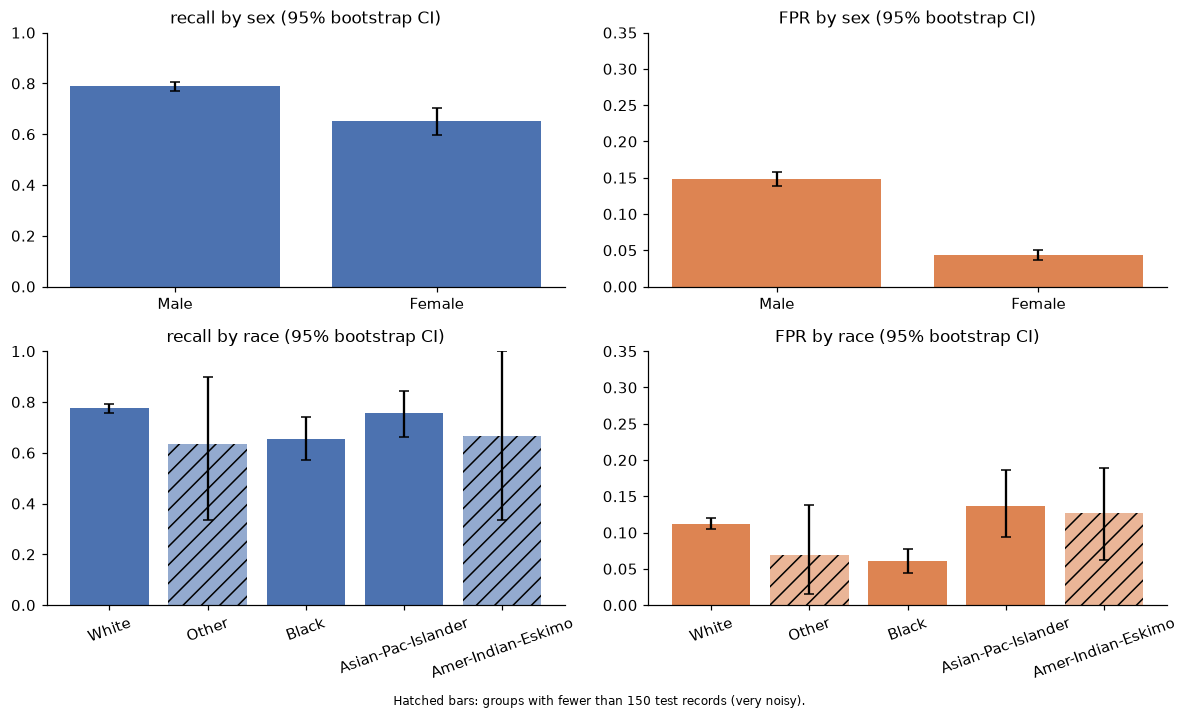

In [32]:
sex_rep = group_report(y_test, y_pred, X_test["sex"], "sex")
race_rep = group_report(y_test, y_pred, X_test["race"], "race")
display(sex_rep); display(race_rep)
ci_sex = group_report_ci(y_test, y_pred, X_test["sex"], "sex", n_boot=1000)
ci_race = group_report_ci(y_test, y_pred, X_test["race"], "race", n_boot=1000)
gaps = gap_ci(y_test, y_pred, X_test["sex"], "Male", "Female", n_boot=2000)
display(pd.DataFrame({k: v for k, v in gaps.items() if k != "groups"}).T.round(3))
display(Image(plots.fairness_groups(ci_sex, ci_race, FIG_DIR)))

**Measured.** Men are predicted to earn >50K much more often than women (34.3% against 11.2%), with a false positive rate of 14.8% against 4.4%. Recall is 0.79 for men and 0.65 for women. The gaps are not noise: the recall gap is 0.137 (95% CI 0.086 to 0.191), the false-positive-rate gap is 0.104 (0.092 to 0.117) and the false-positive-rate ratio is about 3.4 (2.8 to 4.1). The actual >50K rates also differ (30.4% against 11.2%), and the model over-predicts the positive class for men (34.3% predicted against 30.4% actual) but not for women (11.2% against 11.2%).

Across race, White and Black people differ in recall (0.774 against 0.653, gap 0.122, CI 0.038 to 0.210) and in false positive rate (ratio about 1.8, CI 1.4 to 2.5). The two smallest groups (69 and 104 people) have intervals so wide that nothing can be concluded about them.

**Not measured / cannot be concluded.** These numbers show *that* error rates differ, not *why*. Part of the difference reflects real gaps in the 1994 labels, and the model reproduces them. When base rates differ between groups, it is generally not possible to equalise all common fairness criteria (predicted-positive rates, error rates and precision) at the same time, so choosing which to prioritise is a value judgement, not a technical one.

### 9b. Do `relationship` and `marital-status` act as proxies for sex?

`relationship` contains the values Husband and Wife, which should identify sex almost perfectly. The table below checks this, and then compares three versions of the final model by 5-fold out-of-fold predictions **on the training set** (the test set is not touched). All versions use the same tuned gradient boosting, L1 selection and threshold; only the categorical columns change. `sex` is used here only to split the results, never as a feature.

In [33]:
display(pd.crosstab(X_train["relationship"], X_train["sex"]))
ablation = analysis.sex_proxy_ablation(X_train, y_train, best_gb, cv, THRESHOLD, oof_final)
display(ablation.round(3))

sex,Female,Male
relationship,,
Husband,1,15821
Not-in-family,4698,5363
Other-relative,558,660
Own-child,2671,3362
Unmarried,3126,961
Wife,1849,3


,OOF F1,ROC AUC,Male predicted >50K,Male recall,Male FPR,Female predicted >50K,Female recall,Female FPR
variant,,,,,,,,
A: current (marital-status + relationship),0.727,0.927,0.351,0.789,0.160,0.111,0.704,0.039
B: without relationship,0.725,0.927,0.356,0.795,0.165,0.100,0.654,0.033
C: without relationship and marital-status,0.659,0.888,0.299,0.689,0.128,0.153,0.594,0.100


In the crosstab, Husband is almost always male and Wife almost always female, so `relationship` is close to a copy of `sex`. Removing it costs only 0.002 out-of-fold F1 (0.727 to 0.725) but does **not** close the gap: men are flagged 3.6 times as often as women (35.6% against 10.0%), slightly more than before (3.2 times, 35.1% against 11.1%), because `marital-status` carries the same signal. Removing both columns narrows the false-positive-rate gap (12.8% for men against 10.0% for women), but F1 falls from 0.727 to 0.659 and ROC AUC from 0.927 to 0.888, which is a large cost for this task, and women's predicted-positive rate rises to 15.3%. Dropping features therefore does not make the model fair in any simple sense; it moves the errors around.

## 10. Robustness checks

These checks were added after the first version of the analysis. They test whether the headline result depends on incidental choices: duplicated rows across the split, scaling before the L1 selector, the choice of gradient-boosting implementation, the choice of split (the official `adult.data` / `adult.test` files and other random seeds).

**Caveat.** The hyper-parameters were tuned on the seed-42 training set. For the official-split and other-seed checks, some of the new test rows were therefore seen during tuning, so these checks measure *split-to-split variation*, not an unbiased performance estimate. The unbiased estimate remains the single seed-42 test evaluation in section 7.

In [34]:
print("test F1 without the %d rows that also appear in training: %.4f" % (overlap.sum(),
      evaluate_at_threshold(y_test.values[~overlap], y_proba[~overlap], THRESHOLD)["f1"]))
display(pd.DataFrame(analysis.scaled_selector_sensitivity(X_train, y_train, best_gb, cv)).round(4))
display(pd.Series(analysis.hist_gb_benchmark(X_train, y_train, cv), name="HistGradientBoosting (defaults), CV on train").round(4).to_frame())

test F1 without the 18 rows that also appear in training: 0.7276


,setup,f1_at_0.5,roc_auc,avg_features,oof_best_threshold,oof_f1_at_best_threshold
0,L1 selector on raw inputs (as in the final model),0.7102,0.9274,30.8,0.35,0.7272
1,L1 selector on standardised inputs,0.7110,0.9275,29.2,0.34,0.7272


,"HistGradientBoosting (defaults), CV on train"
f1_at_0.5,0.7101
roc_auc,0.9277
oof_best_threshold,0.3600
oof_f1_at_best_threshold,0.7277


In [35]:
official = analysis.official_split_check(train_official, test_official, best_gb)
print("official train -> official test:", {k: round(official[k], 4) for k in ("threshold", "precision", "recall", "f1", "roc_auc")})
seeds = pd.DataFrame(analysis.seed_sensitivity(df, best_gb))
display(seeds.round(4))
display(seeds[["precision", "recall", "f1", "roc_auc"]].agg(["mean", "std"]).round(4))

official train -> official test: {'threshold': 0.4, 'precision': 0.7125, 'recall': 0.727, 'f1': 0.7197, 'roc_auc': 0.9276}


,split_seed,threshold,precision,recall,f1,roc_auc
0,0,0.38,0.7077,0.7622,0.7339,0.9292
1,1,0.37,0.7140,0.7592,0.7359,0.9317
2,2,0.39,0.7333,0.7468,0.7400,0.9329
3,3,0.35,0.6774,0.7896,0.7292,0.9276
4,4,0.39,0.7160,0.7288,0.7223,0.9260


,precision,recall,f1,roc_auc
mean,0.7097,0.7573,0.7323,0.9295
std,0.0204,0.0223,0.0068,0.0029


- **Duplicates:** the test F1 is 0.7276 with or without the 18 test rows that also appear in training.
- **Scaling before the selector:** standardising the numeric inputs before the L1 selector gives the same out-of-fold F1 (0.727) and ROC AUC (0.927), so the scale-dependence of the selector does not matter here.
- **Other implementation:** scikit-learn's `HistGradientBoostingClassifier` with default settings reaches an out-of-fold F1 of 0.728 (AUC 0.928), the same as the tuned model, so the result is not an artefact of this particular implementation or grid.
- **Official split:** training on the official `adult.data` (32,561 rows) and testing on the official `adult.test` (16,281 rows) gives F1 0.720 and ROC AUC 0.928 (threshold 0.40). This is the split most published results use, so this number is the one to compare with the literature.
- **Other seeds:** over five other random splits, test F1 is 0.732 ± 0.007 (range 0.722 to 0.740) and ROC AUC 0.929 ± 0.003. The seed-42 result (F1 0.728) lies inside this range.

## 11. Reflection

This model predicts whether a person earned more than $50K a year in the 1994 census. Its limits start with the data. The labels are over thirty years old, the $50K cutoff means little today, the extract keeps only "reasonably clean" records, and "high income" is partly a household quantity here, because marital status and relationship are among the strongest signals. On the test set the final model reaches an F1 of 0.73 for the >50K class (95% interval 0.71 to 0.74), but it still misses about one in four high earners (recall 0.77), and about three in ten of the people it flags are wrong (precision 0.69). The errors are not random: the false negatives are mostly people with no capital income and an ordinary profile, so the model has almost nothing to go on for them.

Bias is the main concern. Race and sex were not used as features, but the inspection tables show that this does not make the model neutral. Marital status and relationship work as proxies for sex: the values Husband and Wife in `relationship` almost identify it, and marital status was the most important feature in the permutation test. Men are flagged as high earners far more often than women (34.3% versus 11.2%), their false positive rate is about 3.4 times higher (14.8% versus 4.4%), and recall is higher for men (0.79 versus 0.65); the bootstrap intervals show these gaps are not sampling noise. Part of this mirrors real gaps in the 1994 labels, so the model learns and repeats historical inequality instead of anything about an individual. Two of the racial groups are very small (69 and 104 people), so those numbers are too noisy to conclude anything from.

I would not use this model to decide anything about real people, for example credit, hiring or benefits. Before any use, the first thing I would do is a proper fairness audit on current, representative data: compare error rates across sex and race with confidence intervals, repeat the ablation on current data (dropping `relationship` cost only 0.002 F1 and did not narrow the gap, while dropping marital status too cost 0.07 F1), and agree with the people who own the decision which kind of error is worse. The decision threshold (0.35 here) would have to be revisited with that cost in mind, since it deliberately trades precision for recall. If the audit fails, the model should only be used for aggregate analysis, with a human making any individual decision.

### Consistency check against the committed results

`scripts/run_pipeline.py` writes `results/results.json`. The cell below checks that this notebook, run independently, reproduces the key numbers (it is skipped if the file does not exist).

In [37]:
import json
path = DEFAULT_RESULTS_DIR / "results.json"
if path.exists():
    ref = json.loads(path.read_text())
    for key in ("precision", "recall", "f1", "accuracy", "tn", "fp", "fn", "tp"):
        assert abs(ref["test"][key] - test[key]) < 1e-9, f"{key} differs from results.json"
    assert abs(ref["test"]["roc_auc"] - test["roc_auc"]) < 1e-6 and ref["threshold"] == THRESHOLD
    print("Notebook and results/results.json agree (test metrics, confusion matrix, threshold).")
else:
    print("results/results.json not found: run scripts/run_pipeline.py to create it.")
print("notebook runtime: %.0f s" % (time.time() - T0))

Notebook and results/results.json agree (test metrics, confusion matrix, threshold).
notebook runtime: 1848 s
